# Notebook 2 · Integração de arquitetura e estruturas a partir do Notebook 1

**CIV2155 · FNDE Tipo 2 · revisão R03 · Arquitetura, estrutura metálica SMT e estrutura de concreto SCO.**

O mesmo extrator do Notebook 1 é aplicado primeiro à arquitetura e depois às duas estruturas. A base arquitetônica reextraída é conferida contra o resultado atual do N1, cujo enriquecimento é preservado. Os modelos são reunidos em um RDF Dataset com grafos nomeados; relações geométricas verificadas conectam os elementos estruturais aos ambientes.

O procedimento preserva as origens e não cria equivalências a partir de nomes. A reunião dos dados e as ligações geométricas são avaliadas separadamente. Problemas não resolvidos pelas fontes e pelos testes permanecem explicitamente como limitações.

**Referências principais:** [Bonduel et al. (2018), IFCtoLBD](https://ceur-ws.org/Vol-2159/04paper.pdf); [Lilis et al. (2025), GRC](https://doi.org/10.1016/j.autcon.2025.106081); [Rasmussen et al. (2021), BOT](https://doi.org/10.3233/SW-200385), artigo adicional com [versão aberta disponibilizada](../referencias/integracao/Rasmussen_et_al_BOT_versao_aberta.pdf). A matriz de contribuições, adaptações e limites está nas [referências da integração](../referencias/integracao/README.md).

## 1. Importar o código compartilhado e as entradas

O notebook usa a cópia local do repositório ou baixa os arquivos necessários do GitHub, verificando seus hashes. As bibliotecas e o motor seguem o Notebook 1. O código de conversão foi generalizado por parâmetros de hash e namespace, mantendo os padrões anteriores do N1.

O resultado arquitetônico atual do N1 é usado como entrada. Quando ele já foi produzido localmente, a compatibilidade é conferida pelo IFC de origem e pela base semântica reextraída. Se não existir localmente, baixa-se o artefato publicado. Intermediários ficam em `.execucao/notebook2/`; resultados primários ficam em `resultados/integracao/`.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,zipfile,subprocess,importlib.util,csv
from urllib.request import urlretrieve
from importlib.metadata import version
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
RAIZ=Path(os.environ.get('CIV2155_RAIZ',Path.cwd())).resolve()
if not (RAIZ/'codigo').is_dir() and (RAIZ.parent/'codigo').is_dir():RAIZ=RAIZ.parent
if not (RAIZ/'codigo').is_dir():RAIZ=RAIZ/'CIV2155';RAIZ.mkdir(exist_ok=True)
ARQUIVOS = {'codigo/converter_ifc.py': 'ad80504fec74b21543e88c4d6df69bb93eefe46ca6229c8f523a0e4b7e5fb98e', 'codigo/integrar_modelos.py': 'b5850644f94e783b606311acf79a6feb32306c266421cac262e770455941077b', 'codigo/relacoes_interdisciplinares.py': '7d564372c9f457c663b52a61e4cfa59f2f866180cfb6392c2e5d87c30d004e5c', 'codigo/preparar_geometria.py': 'b159077aa2395b01244b7d68920f9983d9e585f5bd63ad156a632def1bfe1363', 'codigo/recuperar_geometria.py': 'f60a376111593ac33b5a7814f121bd49cfa77d22e712879519b30dd8a705b265', 'codigo/ifc2sb_faces.py': '5932ba26c9865bb8152278238ae3e3191dc20deccb0d61576cba6358077a8bd6', 'codigo/apresentar_integracao.py': 'e5ebe88bd056be23e4ae0275e945017b056c3ac5117a72a2b17ada3cf7e7d6ee', 'codigo/visualizar_rdf.py': 'e399ce9cccd281767b866cc48bed0c897b4eba1fa6db99da5f0786b3768451b4', 'codigo/03_modelos_integrados.rq': '6a89675efde6a8dafd65d2dcf7ecf6c052ac1bf274b2241e473517f4aa07c1ea', 'codigo/04_relacoes_estrutura_ambientes.rq': '5b1a7504818f1ca42e5c6af079caf30d163b5212e1f7da9d971c6d56f34ef391', 'codigo/Vocabulario_Integracao.ttl': '719ff42287c6f696c33ef4f505ffc208d9bf09f7502a828de357c728a139919f', 'codigo/COPYING': 'd0495053051967ebe76fb1facd287d79d1ed800da1be75cf501a556bc39a0472', 'LICENSE': '3972dc9744f6499f0f9b2dbf76696f2ae7ad8af9b23dde66d6af86c9dfb36986', 'dados/Modelos_Integracao.json': '53d390bd23ef1bb9835e15c22c443aef913866103032855dab046f21ea569927', 'dados/TIPO2-ARQ-DTV_R03.ifc.zip': '19053ddc0698742ab28b1af2b8ee573bfe96ef5fec4f148d115cc4c8d8bfc770', 'dados/TIPO2-SMT-MOD_R03.ifc.zip': '438a18dba8b2b656383127d9fbcd0ebf44bd4e55a07bfd822af8026209982048', 'dados/TIPO2-SCO-MOD_R03.IFC.zip': '9f9f0574df57606690d85cf1c875b067dd6df21e2e28a2d65bc53bfa26408efe', 'requirements.txt': 'a1b5eaf150f386a65cf3d213baa0853e61abb035b4ba25313ddc4a96553cf3ec'}
for rel,digest in ARQUIVOS.items():
    target=RAIZ/rel;target.parent.mkdir(parents=True,exist_ok=True)
    if not target.exists():urlretrieve('https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/'+rel,target)
    if sha(target)!=digest:raise ValueError('Fonte diferente da versão deste notebook: '+rel)
deps={'numpy':'numpy==2.5.4','ifcopenshell':'ifcopenshell==0.8.4','OCP':'cadquery-ocp==7.8.1.1.post1','shapely':'shapely==2.2.0','rdflib':'rdflib==7.1.4','matplotlib':'matplotlib==3.10.7'}
names={'OCP':'cadquery-ocp'}
missing=[spec for mod,spec in deps.items() if importlib.util.find_spec(mod) is None or version(names.get(mod,mod))!=spec.split('==')[1]]
if missing:subprocess.check_call([sys.executable,'-m','pip','install',*missing])
sys.path.insert(0,str(RAIZ/'codigo'))
TRABALHO=RAIZ/'.execucao/notebook2';TRABALHO.mkdir(parents=True,exist_ok=True)
SAIDA=RAIZ/'resultados/integracao';SAIDA.mkdir(parents=True,exist_ok=True)
GRAFO_N1=RAIZ/'resultados/Arquitetura_Analisada.zip'
if not GRAFO_N1.exists():
    GRAFO_N1.parent.mkdir(parents=True,exist_ok=True)
    urlretrieve('https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/resultados/Arquitetura_Analisada.zip',GRAFO_N1)
CONF=json.loads((RAIZ/'dados/Modelos_Integracao.json').read_text(encoding='utf8'))
print('Código, três IFCs e resultado do Notebook 1 disponíveis.')

Código, três IFCs e resultado do Notebook 1 disponíveis.


## 2. Conferir modelos, unidades e posicionamentos

Os arquivos originais são extraídos sem alteração. A arquitetura usa metros; SMT usa milímetros; SCO usa centímetros. IfcOpenShell entrega as geometrias em metros com `use-world-coords=True` e `convert-back-units=False`, aplicando a cadeia de placements declarada. Não se multiplica novamente a geometria pela unidade da fonte.

As cotas e os nomes de pavimentos são atributos dos modelos. Não são usados para inferir equivalência ou uma translação corretiva. O SCO declara um deslocamento de terreno de −40 m em X; ele já está contido nos placements. Nenhum dos três IFCs declara MapConversion. As verificações locais não constituem validação georreferenciada externa.

Fontes técnicas: [unidades IfcOpenShell](https://docs.ifcopenshell.org/autoapi/ifcopenshell/util/unit/index.html), [posicionamentos](https://docs.ifcopenshell.org/autoapi/ifcopenshell/util/placement/index.html) e [geometria](https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html).

In [2]:
from integrar_modelos import extrair_entradas,extrair_modelos,integrar
from relacoes_interdisciplinares import executar_relacoes
PATHS=extrair_entradas(RAIZ,TRABALHO/'entradas',CONF)
for key,path in PATHS.items():
    print(key,path.name,'fator de comprimento para metro:',CONF['modelos'][key]['fator_comprimento_para_m'],
          'IFC conferido:',sha(path)==CONF['modelos'][key]['sha256_ifc'])

arquitetura TIPO2-ARQ-DTV_R03.ifc fator de comprimento para metro: 1 IFC conferido: True
smt TIPO2-SMT-MOD_R03.ifc fator de comprimento para metro: 0.001 IFC conferido: True
sco TIPO2-SCO-MOD_R03.IFC fator de comprimento para metro: 0.01 IFC conferido: True


## 3. Extrair arquitetura e estrutura com o mesmo núcleo do N1

`extrair_modelos` chama `converter` do Notebook 1 para cada disciplina: IFCtoLBD 2.49.0, mesmos parâmetros semânticos e as mesmas duas correções textuais. A arquitetura mantém suas URIs; SMT e SCO recebem namespaces próprios. O limite de memória Java é um parâmetro de execução, não uma mudança de mapeamento.

`RECONVERTER=True` repete as três extrações. Java 21 JDK é necessário; no Windows, informe `CIV2155_JAVA`. O motor oficial e as fontes das classes corrigidas são verificados por hash. No caso da extensão `.IFC` maiúscula, a CLI dessa versão procura um nome acrescido de `.ifc`; o código usa uma cópia de trabalho com extensão minúscula e bytes conferidos. Não modifica o IFC original.

Cada extração deve preservar os GlobalIds e os nomes dos produtos. A comparação do conjunto de triplas arquitetônicas com o N1 é feita antes da integração. A base ampliada do N1 é mantida, incluindo seus 101 pares ambiente–esquadria.

In [3]:
RECONVERTER=True
EXTRACOES=extrair_modelos(PATHS,CONF,TRABALHO/'semantica',reconverter=RECONVERTER)
print('Extrações concluídas:',{key:path.name for key,path in EXTRACOES.items()})

openjdk version "21.0.12.1" 2026-08-18 LTS


Conversão executada: 56961 triplas; 204.2 s
EXTRAÇÃO arquitetura reutilizada: False


openjdk version "21.0.12.1" 2026-08-18 LTS


Conversão executada: 84933 triplas; 49.9 s
EXTRAÇÃO smt reutilizada: False


openjdk version "21.0.12.1" 2026-08-18 LTS


Conversão executada: 205194 triplas; 227.7 s
EXTRAÇÃO sco reutilizada: False


Extrações concluídas: {'arquitetura': 'modelo.ttl', 'smt': 'modelo.ttl', 'sco': 'modelo.ttl'}


## 4. Verificar relações entre ambientes e elementos estruturais

A checagem cruzada adapta o processo de [Lilis et al. (2025)](https://doi.org/10.1016/j.autcon.2025.106081), §§3.1–3.4: extrair geometria, selecionar pares, usar AABB como pré-filtro, verificar a relação e registrá-la em RDF. A implementação usa OCP, não o GRC/BSP dos autores. Os sólidos são preparados com o mesmo procedimento conservador do N1, derivado parcialmente de IFC2SB, sem caixa substituta ou tampão.

O recorte geométrico contém 3.861 elementos SMT e 1.468 SCO. As 17.755 barras de armadura SCO permanecem na extração semântica; sua geometria não é examinada neste recorte. Assemblies e features de vazios SMT também permanecem semanticamente representados, com exclusão geométrica para evitar confundir agregados/recortes com peças independentes.

Para cada par candidato, mede-se o volume comum. A contenção exige o corpo completo no espaço; interseção parcial exige volume positivo acima do limiar. Sem volume significativo, busca-se uma superfície comum com área positiva. Proximidade, contato por aresta ou por ponto não são promovidos a contato por face. Os limiares são próprios do estudo e permanecem comuns aos cômodos.

[Rasmussen et al. (2021), §3.4](https://doi.org/10.3233/SW-200385), fundamentam `bot:containsElement`, `bot:intersectingElement` e `bot:adjacentElement`. Os nomes físicos das peças não determinam esses vínculos. O resultado descreve o referencial dos arquivos e não certifica adequação estrutural ou erro de projeto.

In [4]:
GEO=executar_relacoes(PATHS['arquitetura'],{k:PATHS[k] for k in ['smt','sco']},TRABALHO/'geometria',SAIDA)
print('Espaços com sólido:',GEO['ambientes_com_solido'],';',GEO['ambientes_inconclusivos'],'inconclusivos')
print('Pares candidatos:',GEO['pares'],'; relações positivas:',GEO['relacoes_positivas'])

PARES smt 100 / 1035 elementos; 112 pares


PARES smt 200 / 1035 elementos; 252 pares


PARES smt 300 / 1035 elementos; 392 pares


PARES smt 400 / 1035 elementos; 496 pares


PARES smt 500 / 1035 elementos; 616 pares


...

PARES sco 300 / 535 elementos; 506 pares


PARES sco 400 / 535 elementos; 668 pares


PARES sco 500 / 535 elementos; 819 pares


{
  "parametros": {
    "margem_aabb_m": 0.0001,
    "volume_min_m3": 1e-09,
    "volume_relativo_min": 1e-08,
    "area_comum_min_m2": 1e-06,
    "distancia_busca_contato_m": 0.0001,
    "tolerancia_contencao_rel": 1e-07
  },
  "ambientes": 41,
  "ambientes_com_solido": 38,
  "ambientes_inconclusivos": 3,
  "por_modelo": [
    {
      "modelo": "smt",
      "elementos_ifc": 5253,
      "alvos_geometricos": 3861,
      "caixas_disponiveis": 3861,
      "elementos_com_candidatos": 1035,
      "elementos_com_preparo_inconclusivo": 0,
      "pares_examinados": 1190,
      "estados": {
        "intersecciona": 758,
        "contido": 196,
        "sem_relacao_no_criterio": 108,
        "proximo_sem_superficie_comum": 4,
        "adjacente": 124
      },
      "metodos_preparo": {
        "caminho_estrito_v09_preservado": 1035
      },
      "classes_fora_do_recorte": {
        "IfcElementAssembly": 1365,
        "IfcVoidingFeature": 27
      }
    },
    {
      "modelo": "sco",
      "ele

Espaços com sólido: 38 ; 3 inconclusivos
Pares candidatos: 2053 ; relações positivas: 1652


## 5. Reunir os modelos e consultar as ligações no RDF

O Dataset mantém cinco grafos nomeados: arquitetura, SMT, SCO, relações interdisciplinares e proveniência. A origem de cada produto continua explícita. Nomes iguais não geram `owl:sameAs`. A federação permite consultas conjuntas sem eliminar identidades ou substituir os contextos de origem.

A implementação usa o modelo de [RDF Datasets do W3C](https://www.w3.org/TR/rdf11-concepts/#section-dataset). O arquivo completo é gravado em [N-Quads](https://www.w3.org/TR/n-quads/), preservando grafos e literais tipados. A reabertura compara contagens e assinaturas semânticas dos cinco grafos; isso evita aceitar apenas a igualdade das contagens quando um literal tiver mudado. As relações também são disponibilizadas em N-Triples.

As consultas percorrem o grafo arquitetônico para identificar o ambiente, o grafo de relações para obter a ligação e o grafo estrutural para recuperar o elemento. Os espaços inconclusivos mantêm contagens indisponíveis.

In [5]:
INTEGRACAO=integrar(GRAFO_N1,PATHS,EXTRACOES,SAIDA,SAIDA)
print('Grafos nomeados:',INTEGRACAO['grafos_nomeados'])
print('Preservação semântica após reabertura:',INTEGRACAO['preservacao_semantica_por_grafo'])
print('Pares do N1 preservados:',INTEGRACAO['pares_n1_preservados'])

GRAFO arquitetura 80234 triplas; 2116 produtos preservados


GRAFO smt 84933 triplas; 5256 produtos preservados


GRAFO sco 205194 triplas; 19229 produtos preservados


C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\desenvolvimento\runtime_validacao\rdflib\plugins\serializers\nt.py:41: UserWarning: NTSerializer always uses UTF-8 encoding. Given encoding was: None
  warnings.warn(


{
  "grafos_nomeados": {
    "arquitetura": 80234,
    "smt": 84933,
    "sco": 205194,
    "relacoes": 18194,
    "proveniencia": 26620
  },
  "quadruplas": 415175,
  "relacoes_interdisciplinares": 1652,
  "pares_n1_preservados": 101,
  "origens_preservadas": true,
  "owl_sameAs_inferido": false,
  "preservacao_semantica_por_grafo": true,
  "formato_dataset": "N-Quads",
  "por_modelo": {
    "smt": 1078,
    "sco": 574
  },
  "por_relacao": {
    "intersecciona": 863,
    "contido": 198,
    "adjacente": 591
  },
  "alcance": "Federação RDF e relações geométricas no referencial dos arquivos. Não certifica coordenação de projeto, função ou adequação estrutural."
}


Grafos nomeados: {'arquitetura': 80234, 'smt': 84933, 'sco': 205194, 'relacoes': 18194, 'proveniencia': 26620}
Preservação semântica após reabertura: True
Pares do N1 preservados: 101


## 6. Ler os resultados e visualizar um exemplo

O gráfico separa contato por face, interseção parcial e contenção. São contagens de pares, não de peças físicas. Um elemento pode relacionar-se a mais de um ambiente.

A figura RDF mostra um exemplo real de contato entre a cozinha e um elemento SCO, com os modelos de origem e a área de contato. A seleção usa o maior contato SCO–cozinha no critério para tornar o exemplo legível; ela não constitui validação independente nem escolha de um elemento arquitetonicamente “correto”.

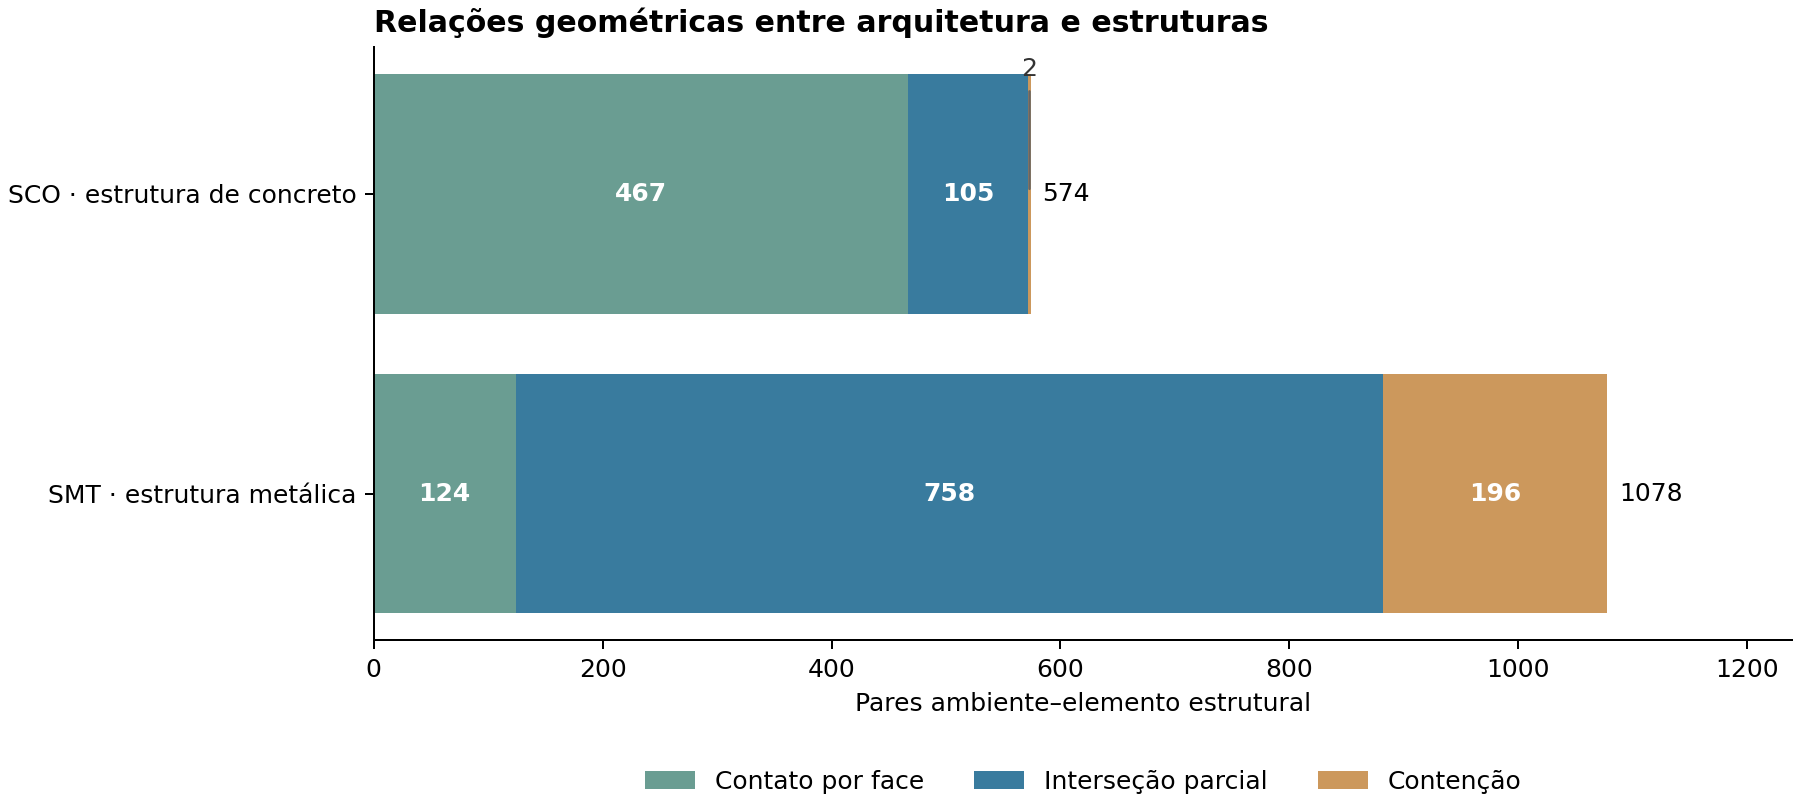

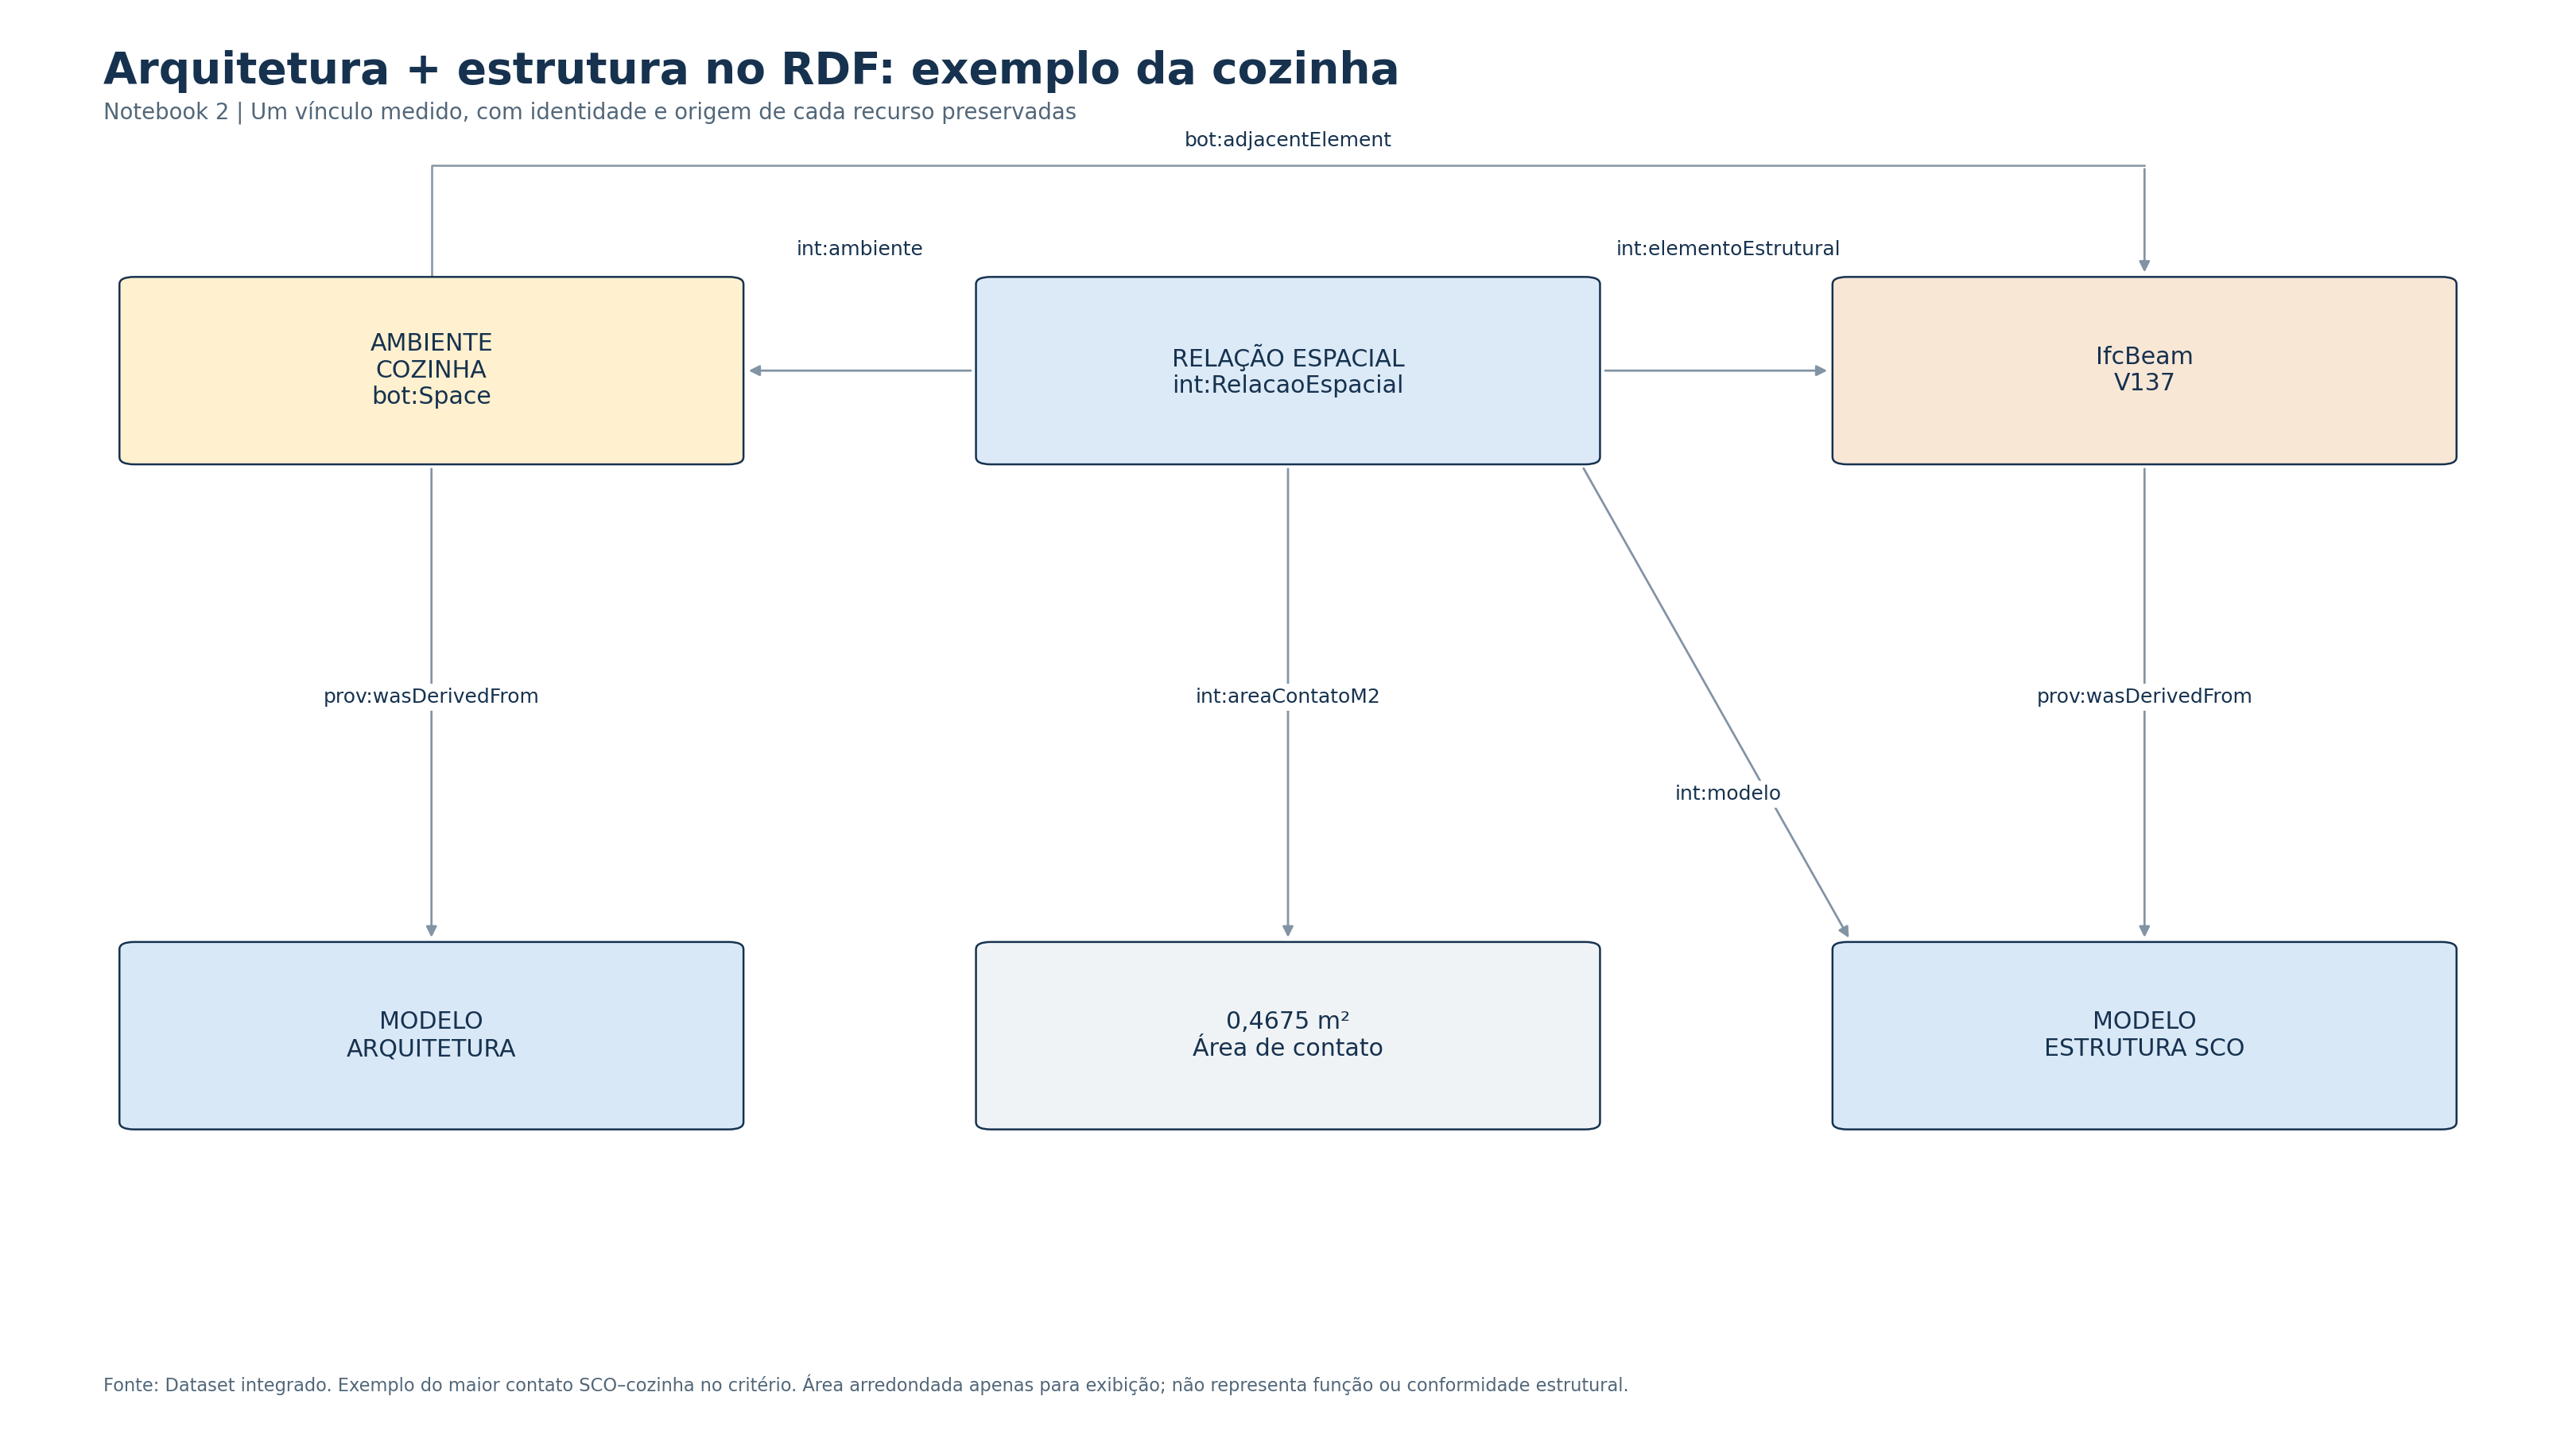

Relações estruturais consultadas para a cozinha: 16
sco P111 adjacente volume: 0.0 área: 0.042
sco V135 adjacente volume: 0.0 área: 0.04525370020731099
sco V137 adjacente volume: 0.0 área: 0.4674837228519026
sco V138 adjacente volume: 0.0 área: 0.0912566637936261
sco V142 adjacente volume: 0.0 área: 0.007734214978106269
sco V143 adjacente volume: 0.0 área: 0.20567640824769012
sco V143 adjacente volume: 0.0 área: 0.09367665321103313
sco V196 adjacente volume: 0.0 área: 0.27354953675541266
sco V196 adjacente volume: 0.0 área: 0.45406539398113704
sco V204 adjacente volume: 0.0 área: 0.08900000000000001
sco V207 adjacente volume: 0.0 área: 0.09997843389976194
sco V210 adjacente volume: 0.0 área: 0.31511350280351785
sco V211 adjacente volume: 0.0 área: 0.08730383997191461
sco V216 adjacente volume: 0.0 área: 0.00024668681219180494
sco V216 adjacente volume: 0.0 área: 0.16968943895965743
sco V303 intersecciona volume: 0.0727974754676336 área: 0.0


In [6]:
from apresentar_integracao import gerar_figuras_integracao
from IPython.display import display,Image,HTML
from html import escape
FIGURAS=gerar_figuras_integracao(SAIDA)
display(Image(filename=str(SAIDA/'Relacoes_Por_Modelo.png'),width=1000))
display(Image(filename=str(SAIDA/'Grafo_Integracao_Cozinha.png'),width=1100))
with (SAIDA/'Consulta_Relacoes.csv').open(encoding='utf-8-sig') as fp:
    cozinha=[r for r in csv.DictReader(fp) if r['nome_ambiente']=='COZINHA']
print('Relações estruturais consultadas para a cozinha:',len(cozinha))
for r in cozinha:print(r['modelo'],r['nome_elemento'],r['estado'],'volume:',r['volume_m3'],'área:',r['area_m2'])

## 7. Limitações da integração

1. **Três espaços permanecem inconclusivos:** Infantil 1, Infantil 5 e Amamentação. Nenhuma relação é inferida a partir de uma caixa para suprir seus volumes.
2. **Alinhamento externo não demonstrado:** os placements e as unidades são tratados conforme os IFCs. Os arquivos não declaram MapConversion; não há verificação topográfica externa nem ajuste automático entre modelos.
3. **Equivalência de pavimentos/entidades não estabelecida:** os nomes e cotas diferem entre os modelos. A federação conserva recursos separados e não afirma que pavimentos de mesmo nome são a mesma entidade física.
4. **Recorte geométrico limitado:** armaduras, assemblies e features de vazios continuam na informação semântica, mas não são tratados como peças independentes na checagem descrita. As contagens não representam a verificação geométrica de toda a estrutura.
5. **Validação arquitetônica/estrutural pendente:** não há referência independente para todos os 1.652 vínculos observados nesta versão. Relações geométricas não determinam função, adequação ou erro de projeto. A validade de um sólido também não resolve eventuais sobreposições entre ambientes da fonte.
6. **Precisão e propriedades:** os critérios dependem das representações e tolerâncias dos modelos. A geometria é expressa em SI; outras propriedades permanecem nos contextos de origem, sem harmonização geral de quantidades ou significados.

Esses são limites do procedimento e da evidência disponíveis nesta execução. Não se afirma que a literatura inteira seja incapaz de resolvê-los. As melhorias futuras precisam de fundamentação, dados e testes específicos; não são preenchidas por equivalências ou transformações presumidas.

In [7]:
assert INTEGRACAO['preservacao_semantica_por_grafo']
assert INTEGRACAO['pares_n1_preservados']==101
assert all(sha(path)==CONF['modelos'][key]['sha256_ifc'] for key,path in PATHS.items())
print('Integração executada, consultas conferidas e IFCs originais preservados.')
print('A interpretação fica limitada ao referencial, às categorias geométricas e às validações documentadas acima.')

Integração executada, consultas conferidas e IFCs originais preservados.
A interpretação fica limitada ao referencial, às categorias geométricas e às validações documentadas acima.
